# Regresion lineal para predecir la progresion de la diabetes

En este laboratorio se usa el conjunto de datos `Diabetes` de scikit-learn. La idea es entrenar un modelo de regresion lineal y revisar su rendimiento con MSE, RMSE, MAE y R2.

Las variables son edad, sexo, IMC, presion arterial y seis mediciones de sangre. La variable `target` representa la progresion de la enfermedad un año despues.

In [1]:
# Librerias necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

plt.style.use('seaborn-v0_8-whitegrid')

## 1. Carga y revision de los datos

In [2]:
diabetes = load_diabetes()
df = pd.DataFrame(diabetes.data, columns=diabetes.feature_names)
df['target'] = diabetes.target

print('Filas y columnas:', df.shape)
df.head()

Filas y columnas: (442, 11)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [3]:
print('Datos faltantes:', int(df.isna().sum().sum()))
print('
Resumen de la variable objetivo:')
df['target'].describe()

Datos faltantes: 0

Resumen de la variable objetivo:


count    442.000000
mean     152.133484
std       77.093005
min       25.000000
25%       87.000000
50%      140.500000
75%      211.500000
max      346.000000

## 2. Preparacion de los datos

In [4]:
X = df.drop(columns='target')
y = df['target']

# Se reserva 20% para probar el modelo con datos qeu no vio durante el entrenamiento
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print('Datos para entrenamiento:', X_train.shape)
print('Datos para prueba:', X_test.shape)

Datos para entrenamiento: (353, 10)
Datos para prueba: (89, 10)


## 3. Entrenamiento del modelo

In [5]:
# El escalado y la regresion se colocan en un mismo flujo
modelo = Pipeline([
    ('escalado', StandardScaler()),
    ('regresion', LinearRegression())
])

modelo.fit(X_train, y_train)
predicciones = modelo.predict(X_test)
print('Modelo entrenado correctamente')

Modelo entrenado correctamente


## 4. Evaluacion final

In [6]:
mse = mean_squared_error(y_test, predicciones)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, predicciones)
r2 = r2_score(y_test, predicciones)

print('EVALUACION FINAL DEL MODELO')
print(f'MSE:  {mse:.2f}')
print(f'RMSE: {rmse:.2f}')
print(f'MAE:  {mae:.2f}')
print(f'R2:   {r2:.4f}')

EVALUACION FINAL DEL MODELO
MSE:  2900.19
RMSE: 53.85
MAE:  42.79
R2:   0.4526


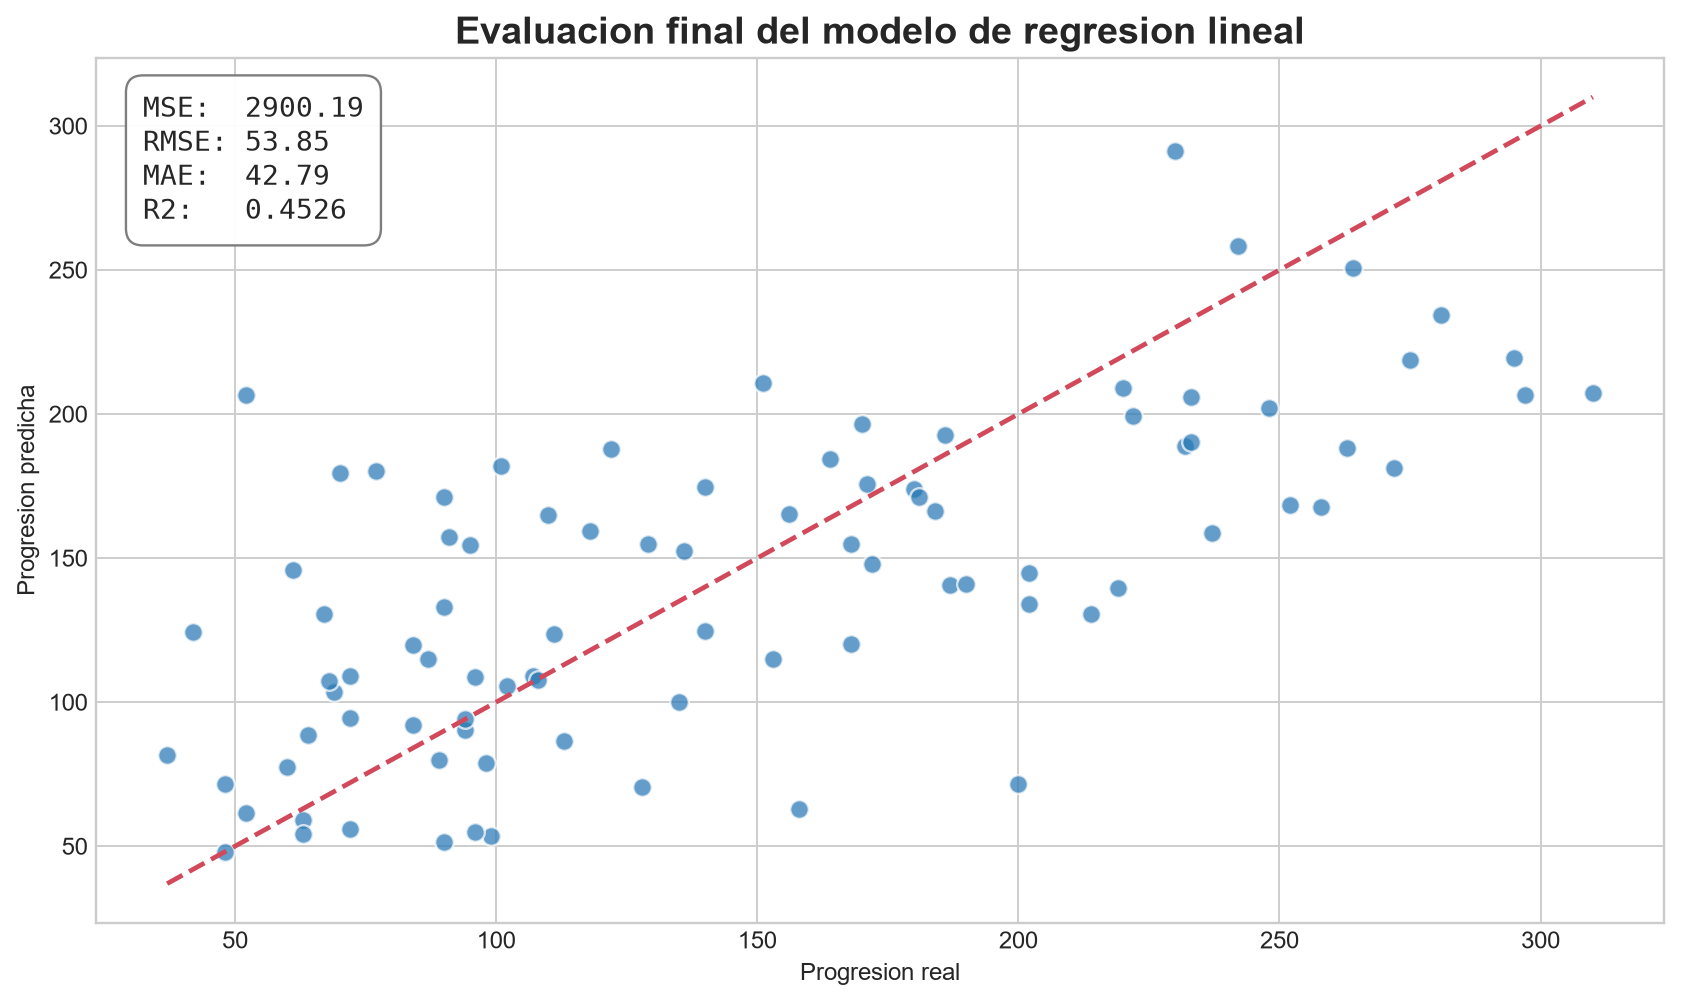

In [7]:
# Grafica con valores reales y predicciones
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(y_test, predicciones, alpha=0.72, color='#2878b5', edgecolor='white', s=62)
limite_min = min(y_test.min(), predicciones.min())
limite_max = max(y_test.max(), predicciones.max())
ax.plot([limite_min, limite_max], [limite_min, limite_max], '--', color='#d1495b', linewidth=2)
ax.set_title('Evaluacion final del modelo de regresion lineal', fontsize=16, weight='bold')
ax.set_xlabel('Progresion real')
ax.set_ylabel('Progresion predicha')

metricas = (
    f'MSE:  {mse:.2f}
'
    f'RMSE: {rmse:.2f}
'
    f'MAE:  {mae:.2f}
'
    f'R2:   {r2:.4f}'
)
ax.text(
    0.03, 0.96, metricas, transform=ax.transAxes, va='top',
    fontsize=12, family='monospace',
    bbox=dict(boxstyle='round,pad=0.6', facecolor='white', edgecolor='#777777', alpha=0.95)
)
fig.tight_layout()
fig.savefig('captura_metricas_modelo.png', dpi=170, bbox_inches='tight')
plt.show()

## 5. Variables con mayor influencia

In [8]:
coeficientes = pd.DataFrame({
    'variable': X.columns,
    'coeficiente': modelo.named_steps['regresion'].coef_
})
coeficientes['impacto_absoluto'] = coeficientes['coeficiente'].abs()
coeficientes.sort_values('impacto_absoluto', ascending=False).drop(columns='impacto_absoluto')

variable,coeficiente
s1,-44.448856
s5,35.161195
bmi,25.607121
s2,24.640954
bp,16.828872
s4,13.138784
sex,-11.511809
s3,7.676978
s6,2.351364
age,1.753758


## Conclusion

El modelo explica cerca del 45% de la variacion observada en los datos de prueba. El RMSE queda alrededor de 54 puntos, por lo qeu las predicciones son utiles como una aproximacion, aunque todavia existe un error importante. Tambien se observa que algunas variables, como el IMC y ciertas mediciones de sangre, tienen mayor peso en la prediccion. Para mejorar el resultado se podrian comparar otros modelos y realizar validacion cruzada.